# 01 Explore One Route
**Goal:** Explore the M15 route to determine if the 2023-24 and 2025 data sets are comparable segment-by-segment. Compare the data from January 2024 to the data from January 2025.

## Setup

In [1]:
# Imports
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

from nyc_congestion_bus_speeds.cleaning import snake_case_columns

In [2]:
# Folders
RAW_DIR = Path("../data/raw")
PROCESSED_DIR = Path("../data/processed")
RAW_DIR.mkdir(parents=True, exist_ok=True)
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)

# Data paths
CSV_2023_24 = RAW_DIR / "segment_speeds_2023_24.csv"
CSV_2025 = RAW_DIR / "segment_speeds_2025.csv"

# Analysis settings
ROUTE_IDS = ["M15", "M15+"]
USECOLS = [
    "Year", "Month", "Day of Week", "Hour of Day",
    "Route ID", "Direction",
    "Timepoint Stop ID", "Timepoint Stop Name",
    "Next Timepoint Stop ID", "Next Timepoint Stop Name",
    "Road Distance", "Average Travel Time", "Bus Trip Count",
]
SEGMENT_KEY = ["route_id", "direction", "timepoint_stop_id", "next_timepoint_stop_id"]
WEEKDAYS = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday"]

## 1. What's in the data
**Goal:** learn the column names, units, and how dates and days are coded, and check both files use the same columns

In [3]:
peek24 = snake_case_columns(pd.read_csv(CSV_2023_24, nrows=5))
peek24.T

,0,1,2,3,4
year,2023,2023,2023,2023,2023
month,3,3,3,3,3
timestamp,2023 Mar 01 09:00:00 AM,2023 Mar 01 01:00:00 PM,2023 Mar 01 01:00:00 AM,2023 Mar 01 01:00:00 PM,2023 Mar 01 12:00:00 PM
day_of_week,Friday,Friday,Friday,Friday,Friday
hour_of_day,9,13,1,13,12
route_id,B6,B6,BX42,BXM1,BXM1
direction,W,W,E,N,S
borough,Brooklyn,Brooklyn,Bronx,Bronx,Bronx
route_type,Limited,Limited,Local,Express,Express
stop_order,1,1,29,13,29


In [4]:
peek25 = snake_case_columns(pd.read_csv(CSV_2025, nrows=5))
peek25.T

,0,1,2,3,4
year,2025,2025,2025,2025,2025
month,2,2,2,2,2
timestamp,2025 Feb 01 05:00:00 AM,2025 Feb 01 07:00:00 AM,2025 Feb 01 07:00:00 AM,2025 Feb 01 01:00:00 PM,2025 Feb 01 02:00:00 PM
day_of_week,Friday,Friday,Friday,Friday,Friday
hour_of_day,5,7,7,13,14
route_id,B38,B38,B38,BX16,M12
direction,E,E,E,E,S
borough,Brooklyn,Brooklyn,Brooklyn,Bronx,Manhattan
route_type,Local,Local,Limited,Local,Local
stop_order,1,1,1,21,10


In [5]:
# Take the symmetric difference to see if the columns are the same
set(peek24.columns) ^ set(peek25.columns)

set()

**Findings:**
- The CSV uses display names, so columns are converted to snake_case via `snake_case_columns()` to make them easier to work with.
- Both files have the same 24 columns, based on the empty set returned by the symmetric difference.
- Date is stored in `year` and `month` as integers.
- `hour_of_day` is stored as an integer (0 to 23, per the online documentation).
- `day_of_week` is stored as a string (e.g. "Friday", confirmed with full dataset in section 3).
- `timestamp` is stored in the format "YYYY Mon 01 HH:00:00 AM/PM", and duplicates `year`, `month`, and `hour_of_day`, so it can be ignored.
- `road_distance` is stored in miles, `average_travel_time` in minutes, and `average_road_speed` in miles per hour.

## 2. Which route IDs are the M15
**Goal:** Determine which `route_id` values correspond with the M15 route, and decide which to keep. Additionally, check if the `route_id` values are the same in both datasets.

In [6]:
routes24 = snake_case_columns(pd.read_csv(CSV_2023_24, usecols=["Route ID"]))
routes24.loc[routes24["route_id"].str.startswith("M15"), "route_id"].value_counts()

route_id
M15     95379
M15+    24791
Name: count, dtype: int64

In [7]:
routes25 = snake_case_columns(pd.read_csv(CSV_2025, usecols=["Route ID"]))
routes25.loc[routes25["route_id"].str.startswith("M15"), "route_id"].value_counts()

route_id
M15     81587
M15+    20931
Name: count, dtype: int64

**Findings:**
- Both datasets have route IDs "M15" (local) and "M15+" (Select Bus Service).
- The number of rows is in about a 4:1 ratio favoring "M15".
- Both sets will be kept, as they are both part of the same corridor.

## 3. Load January 2024 and January 2025
**Goal:** Load the January 2024 and January 2025 data for both routes. Then, filter to only include needed columns, save the filtered data, check row counts and how `day_of_week` is coded.

In [8]:
def load_january(csv_path, year, out_path):
    """Load one January of M15 data from the full CSV, caching the result as parquet."""
    if out_path.exists():
        return pd.read_parquet(out_path)

    df = snake_case_columns(pd.read_csv(csv_path, usecols=USECOLS))
    df = df[ (df["year"] == year) & (df["month"] == 1) & (df["route_id"].isin(ROUTE_IDS)) ]
    df.to_parquet(out_path, index=False)
    return df

In [9]:
jan24 = load_january(CSV_2023_24, 2024, PROCESSED_DIR / "m15_2024-01.parquet")
jan25 = load_january(CSV_2025, 2025, PROCESSED_DIR / "m15_2025-01.parquet")

In [10]:
print(f"January 2024 Shape: {jan24.shape}")

print(f"January 2025 Shape: {jan25.shape}")

days = pd.concat(
    [jan24["day_of_week"].value_counts(), jan25["day_of_week"].value_counts()],
    axis=1,
    keys=["jan24", "jan25"],
)
days

January 2024 Shape: (5044, 13)
January 2025 Shape: (4865, 13)


,jan24,jan25
day_of_week,,
Monday,752,708
Wednesday,737,718
Friday,730,697
Tuesday,727,705
Thursday,722,696
Saturday,699,667
Sunday,677,674


**Findings:**
- Both datasets have a similar amount of rows (about 5k each).
- Confirmed the spellings of `day_of_week`.

## 4. Do segments match across years
**Goal:** Check how segments match across years, and what share of trips are on matching segments.

In [11]:
# Data for each segment is currently split across multiple rows corresponding to different days and hours
# To fix this, group per segment and sum trips over all days and hours

seg24 = jan24.groupby(SEGMENT_KEY).agg(
    trips=("bus_trip_count", "sum"),
    from_stop=("timepoint_stop_name", "first"),
    to_stop=("next_timepoint_stop_name", "first"),
).reset_index()

seg25 = jan25.groupby(SEGMENT_KEY).agg(
    trips=("bus_trip_count", "sum"),
    from_stop=("timepoint_stop_name", "first"),
    to_stop=("next_timepoint_stop_name", "first"),
).reset_index()

In [12]:
# Now I analyze how some segments may have been added, removed, or renamed between 2024 and 2025
matched = seg24.merge(seg25, on=SEGMENT_KEY, how="outer", suffixes=("_24", "_25"), indicator=True)
display(matched["_merge"].value_counts())

# Weight the match rate by number of trips, not number of segments
match_rate_24 = matched[matched["_merge"] == "both"]["trips_24"].sum() / matched["trips_24"].sum()
match_rate_25 = matched[matched["_merge"] == "both"]["trips_25"].sum() / matched["trips_25"].sum()

print(f"2024: {match_rate_24:.1%}")
print(f"2025: {match_rate_25:.1%}")

_merge
both          27
left_only      3
right_only     3
Name: count, dtype: int64

2024: 87.7%
2025: 87.9%


In [13]:
# Now isolate unmatched segments to get a better idea of what is different between the two years
unmatched = matched[matched["_merge"] != "both"]

unmatched[["_merge", "route_id", "direction", "from_stop_24", "to_stop_24", "from_stop_25", "to_stop_25", "trips_24", "trips_25"]]

,_merge,route_id,direction,from_stop_24,to_stop_24,from_stop_25,to_stop_25,trips_24,trips_25
22,left_only,M15+,N,1 AV/E 14 ST,1 AV/ E 97 ST,NaN,NaN,4399.0,NaN
24,right_only,M15+,N,NaN,NaN,1 AV/E 15 ST,1 AV/ E 97 ST,NaN,4476.0
25,right_only,M15+,N,NaN,NaN,SOUTH FERRY TERM/SOUTH FERRY TERM,1 AV/E 1 ST,NaN,3950.0
26,left_only,M15+,N,SOUTH FERRY/TERMINAL,1 AV/E 1 ST,NaN,NaN,3829.0,NaN
27,left_only,M15+,N,1 AV/E 1 ST,1 AV/E 14 ST,NaN,NaN,4399.0,NaN
28,right_only,M15+,N,NaN,NaN,1 AV/E 1 ST,1 AV/E 15 ST,NaN,4482.0


In [14]:
# Check whether the South Ferry stop moved or renumbered
for label, df in [("2024", jan24), ("2025", jan25)]:
    south_ferry = df[(df["route_id"] == "M15+") & df["timepoint_stop_name"].str.contains("SOUTH FERRY")]
    print(label)
    print(south_ferry[["timepoint_stop_id", "timepoint_stop_name", "next_timepoint_stop_id", "road_distance"]].drop_duplicates())

2024
      timepoint_stop_id   timepoint_stop_name  next_timepoint_stop_id  \
1338             803121  SOUTH FERRY/TERMINAL                  903093   

      road_distance  
1338          2.286  
2025
     timepoint_stop_id                timepoint_stop_name  \
805             405382  SOUTH FERRY TERM/SOUTH FERRY TERM   

     next_timepoint_stop_id  road_distance  
805                  903093           2.29  


**Findings:**
- 27 out of the 30 segments match across the two years, and the trip-weighted match rate is ~88% for both.
- The mismatches were caused by the following:
    - The M15+ northbound timepoint moved from 14 St to 15 St, changing both segments touching it.
    - The South Ferry terminal stop ID was renumbered (evidenced by an identical next stop and nearly identical distances of 2.286 vs. 2.29 mi).
- The segments from 14th St and 15th St to 97th St cross the 60th St congestion pricing line, so classifying them as inside or outside the pricing zone could misrepresent the data.
- A possible later improvement is to automatically merge adjacent unmatched segments (e.g. here one segment from 1st St to 97th St could be created, valid for both years).
- Another possible improvement is to automatically merge unmatched nearby stops (e.g. the two South Ferry Terminal stops).
- Unmatched segments are dropped, as they changed for reasons unrelated to the toll. This costs ~12% of M15 trips.
- Segment IDs are largely consistent across the two years, so the main design works as-is.

## 5. Weekday speed by hour
**Goal:** Compare weekday speeds by hour in January 2024 vs January 2025, only in segments that exist across both years.

In [15]:
keep = matched.loc[matched["_merge"] == "both", SEGMENT_KEY]
both_years = pd.concat([jan24, jan25])
both_years = both_years.merge(keep, on=SEGMENT_KEY)

weekday = both_years[both_years["day_of_week"].isin(WEEKDAYS)]

print(f"Both Years Shape: {both_years.shape}")
print(f"Weekday Shape: {weekday.shape}")

Both Years Shape: (9134, 13)
Weekday Shape: (6609, 13)


In [16]:
weekday["total_miles"] = weekday["road_distance"] * weekday["bus_trip_count"]
weekday["total_minutes"] = weekday["average_travel_time"] * weekday["bus_trip_count"]

speed_by_hour = weekday.groupby(["year", "hour_of_day"])[["total_miles", "total_minutes"]].sum()

speed_by_hour["mph"] = speed_by_hour["total_miles"] / (speed_by_hour["total_minutes"] / 60)

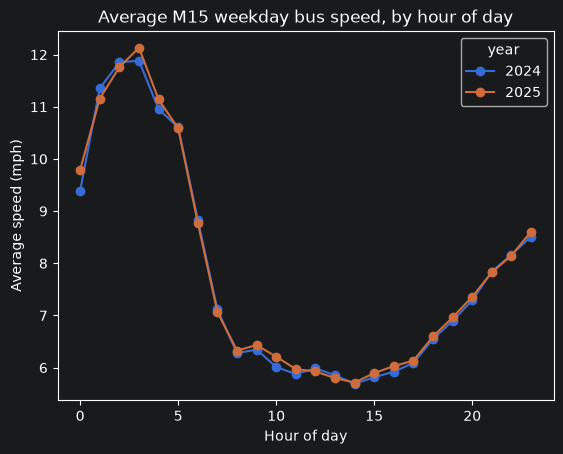

In [17]:
mph_wide = speed_by_hour["mph"].unstack("year")

ax = mph_wide.plot(marker="o")
ax.set_xlabel("Hour of day")
ax.set_ylabel("Average speed (mph)")
ax.set_title("Average M15 weekday bus speed, by hour of day")

plt.show()

### Check: Do weekends lack rush hour traffic patterns?

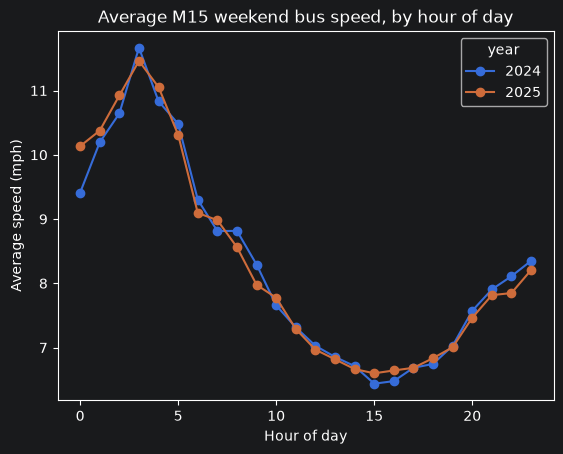

In [18]:
# I assumed that weekends have a different traffic pattern not corresponding to rush hour traffic, so I will check this assumption
weekend = both_years[~both_years["day_of_week"].isin(WEEKDAYS)]

weekend["total_miles"] = weekend["road_distance"] * weekend["bus_trip_count"]
weekend["total_minutes"] = weekend["average_travel_time"] * weekend["bus_trip_count"]

speed_by_hour_weekend = weekend.groupby(["year", "hour_of_day"])[["total_miles", "total_minutes"]].sum()

speed_by_hour_weekend["mph"] = speed_by_hour_weekend["total_miles"] / (speed_by_hour_weekend["total_minutes"] / 60)

mph_wide_weekend = speed_by_hour_weekend["mph"].unstack("year")

ax_weekend = mph_wide_weekend.plot(marker="o")
ax_weekend.set_xlabel("Hour of day")
ax_weekend.set_ylabel("Average speed (mph)")
ax_weekend.set_title("Average M15 weekend bus speed, by hour of day")

plt.show()

**Findings:**
- The weekday speed by hour chart shows a clear rush hour pattern. Speeds are fast overnight, dropping sharply in the morning. Speeds remain low until the afternoon, recovering into the night. The speeds themselves are reasonable, falling within the 6-12mph range.
- There is no clear difference by eye between the years, which is to be expected, as M15 runs both inside and outside the zone, and there is no comparison group.
- The weekend speed by hour chart shows a drop into the afternoon, but it is not as sharp and does not go as slow. This confirms the assumption that weekdays and weekends have different traffic patterns.

## Summary
The datasets are comparable segment by segment, as \~88% of trips run on segments appearing in both years. Comparing the two years by segments, the speeds appear plausible and follow the same daily pattern, indicating the data is consistent across the two sources. I found the mismatches were due to a real timepoint change and renumbered stop. In the future, unmatched segments will be dropped (\~12% of M15 trips), and I now have multiple strategies (merging by adjacent segments and nearby locations) to mitigate that issue if match rates become too low. The column renaming is a step that should be reapplied in the future, as it made it much simpler and more intuitive to work with the data. Lastly, the M15+ segment from 14th/15th St to 97th St crosses the 60th St boundary, so it doesn't fall cleanly inside or outside the zone.